In [1]:
# Step 1: Load and inspect data for Linear Regression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/cleaned/jps_coastal_erosion_cleaned_144.csv"
)

print("=== LINEAR REGRESSION DATA INSPECTION ===")

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nHistorical data columns:")
historical_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in ["year", "date", "shoreline", "position"]
    )
]

print(historical_columns)

print("\nAvailable erosion records:")
print(
    df["Annual_Erosion_Rate_m_yr"]
    .describe()
    .round(2)
)

=== LINEAR REGRESSION DATA INSPECTION ===
Dataset shape: (144, 18)

Available columns:
['No', 'Coastal_Cell', 'District', 'Area_Location', 'Longitude_DMS', 'Latitude_DMS', 'Longitude_DD', 'Latitude_DD', 'Annual_Erosion_Rate_m_yr', 'Physical_Erosion_Score', 'Economic_Score', 'Total_Score', 'ISMP_2022_Category', 'NCES_2015_Category', 'Is_Protected', 'Original_Total_Score', 'Total_Score_Cleaned', 'Is_Erosion_Outlier']

Historical data columns:
[]

Available erosion records:
count    135.00
mean       2.35
std        2.44
min        0.00
25%        0.96
50%        1.66
75%        2.79
max       15.52
Name: Annual_Erosion_Rate_m_yr, dtype: float64


In [6]:
# Step 2: Prepare original JPS data for Linear Regression

from sklearn.model_selection import train_test_split

# Use only original JPS measurements
# Exclude protected locations without erosion-rate measurements
df_lr = df[
    (df["Is_Protected"] == 0) &
    (df["Annual_Erosion_Rate_m_yr"].notna())
].copy()

# Select input features and target
features = ["Longitude_DD", "Latitude_DD"]
target = "Annual_Erosion_Rate_m_yr"

X = df_lr[features]
y = df_lr[target]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=== LINEAR REGRESSION DATA PREPARATION ===")
print("Total records:", len(df_lr))
print("Input features:", features)
print("Target:", target)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Missing input values:", X.isnull().sum().sum())

=== LINEAR REGRESSION DATA PREPARATION ===
Total records: 135
Input features: ['Longitude_DD', 'Latitude_DD']
Target: Annual_Erosion_Rate_m_yr
Training records: 108
Testing records: 27
Missing input values: 0


In [7]:
# Step 3: Train Linear Regression Model

from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train using 80% of the dataset
lr_model.fit(X_train, y_train)

# Predict erosion rates for testing data
y_pred = lr_model.predict(X_test)

print("=== LINEAR REGRESSION TRAINING ===")

print("Model trained successfully!")

print("\nInput features:")
print(features)

print("\nModel coefficients:")
for feature, coef in zip(features, lr_model.coef_):
    print(f"{feature}: {coef:.4f}")

print("\nIntercept:", round(lr_model.intercept_, 4))

print("\nTotal predictions:", len(y_pred))

print("\nFirst 5 predictions:")
print(y_pred[:5].round(2))

=== LINEAR REGRESSION TRAINING ===
Model trained successfully!

Input features:
['Longitude_DD', 'Latitude_DD']

Model coefficients:
Longitude_DD: -5.9404
Latitude_DD: -3.2774

Intercept: 632.0868

Total predictions: 27

First 5 predictions:
[1.94 1.93 2.04 3.25 1.86]


In [8]:
# Step 4: Evaluate Linear Regression Performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate Linear Regression
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Baseline: predict the training-set average erosion rate
baseline_pred = np.full(
    len(y_test),
    y_train.mean()
)

baseline_r2 = r2_score(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("=== LINEAR REGRESSION PERFORMANCE ===")

print("\nLinear Regression:")
print(f"R² Score: {r2:.4f}")
print(f"MAE: {mae:.4f} m/year")
print(f"RMSE: {rmse:.4f} m/year")

print("\nBaseline (Training Mean):")
print(f"R² Score: {baseline_r2:.4f}")
print(f"MAE: {baseline_mae:.4f} m/year")
print(f"RMSE: {baseline_rmse:.4f} m/year")

print("\nModel better than baseline (MAE):",
      mae < baseline_mae)

print("Negative erosion-rate predictions:",
      (y_pred < 0).sum())

=== LINEAR REGRESSION PERFORMANCE ===

Linear Regression:
R² Score: 0.2692
MAE: 1.3254 m/year
RMSE: 1.7284 m/year

Baseline (Training Mean):
R² Score: -0.0026
MAE: 1.4878 m/year
RMSE: 2.0246 m/year

Model better than baseline (MAE): True
Negative erosion-rate predictions: 0


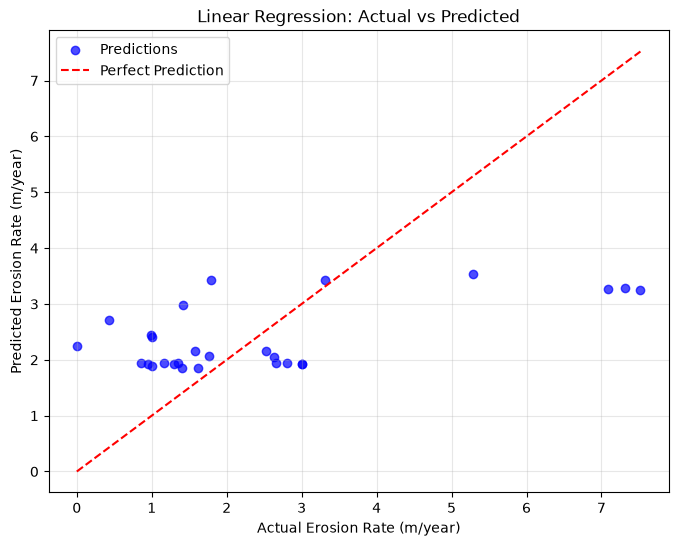

Actual vs Predicted graph saved successfully!


In [5]:
# Step 5: Actual vs Predicted Erosion Rates

import matplotlib.pyplot as plt
import numpy as np
import os

plt.figure(figsize=(8, 6))

# Actual vs predicted values
plt.scatter(
    y_test,
    y_pred,
    color="blue",
    alpha=0.7,
    label="Predictions"
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Erosion Rate (m/year)")
plt.ylabel("Predicted Erosion Rate (m/year)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True, alpha=0.3)

# Save figure
os.makedirs("../results", exist_ok=True)

plt.savefig(
    "../results/linear_regression_actual_vs_predicted_144.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted graph saved successfully!")

=== RESIDUAL ERROR ANALYSIS ===

Average Absolute Error:
1.3254

Top 5 Largest Prediction Errors:
    Actual  Predicted  Residual  Absolute_Error
3     7.52       3.25      4.27            4.27
22    7.32       3.29      4.03            4.03
23    7.09       3.26      3.83            3.83
8     0.43       2.71     -2.28            2.28
12    0.00       2.25     -2.25            2.25


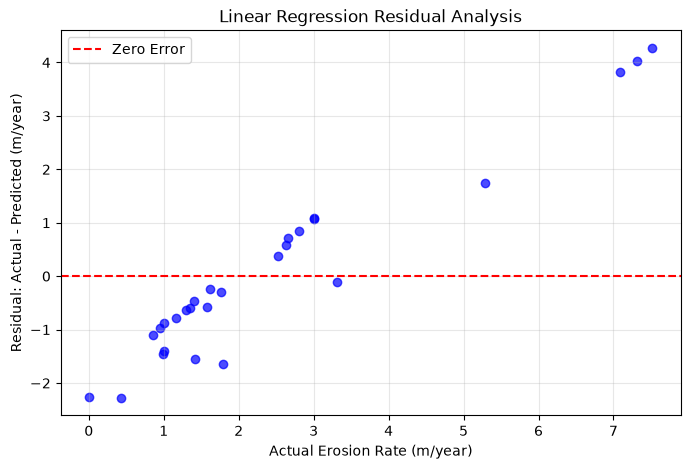

In [6]:
# Step 6: Linear Regression Residual Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Calculate prediction errors
residuals = np.array(y_test) - np.array(y_pred)

error_df = pd.DataFrame({
    "Actual": np.array(y_test),
    "Predicted": np.array(y_pred),
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
})

print("=== RESIDUAL ERROR ANALYSIS ===")

print("\nAverage Absolute Error:")
print(round(error_df["Absolute_Error"].mean(), 4))

print("\nTop 5 Largest Prediction Errors:")
print(
    error_df.nlargest(5, "Absolute_Error").round(2)
)

# Plot residuals
plt.figure(figsize=(8, 5))

plt.scatter(
    error_df["Actual"],
    error_df["Residual"],
    color="blue",
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Actual Erosion Rate (m/year)")
plt.ylabel("Residual: Actual - Predicted (m/year)")
plt.title("Linear Regression Residual Analysis")

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(
    "../results/linear_regression_residuals_144.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Step 7: Spatial Validation by Coastal Cell

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Separate training and testing by coastal cell
groups = df_lr["Coastal_Cell"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train_sp = X.iloc[train_idx]
X_test_sp = X.iloc[test_idx]

y_train_sp = y.iloc[train_idx]
y_test_sp = y.iloc[test_idx]

# Train a separate model for spatial validation
lr_spatial = LinearRegression()
lr_spatial.fit(X_train_sp, y_train_sp)

y_pred_sp = lr_spatial.predict(X_test_sp)

# Evaluate
sp_r2 = r2_score(y_test_sp, y_pred_sp)
sp_mae = mean_absolute_error(y_test_sp, y_pred_sp)
sp_rmse = np.sqrt(
    mean_squared_error(y_test_sp, y_pred_sp)
)

# Compare against training-mean baseline
baseline_sp = np.full(
    len(y_test_sp),
    y_train_sp.mean()
)

baseline_sp_mae = mean_absolute_error(
    y_test_sp, baseline_sp
)

print("=== SPATIAL VALIDATION ===")

print("Training records:", len(X_train_sp))
print("Testing records:", len(X_test_sp))

print("\nHeld-out coastal cells:")
print(sorted(groups.iloc[test_idx].unique()))

print("\nSpatial Validation Performance:")
print(f"R² Score: {sp_r2:.4f}")
print(f"MAE: {sp_mae:.4f} m/year")
print(f"RMSE: {sp_rmse:.4f} m/year")

print("\nBaseline MAE:")
print(f"{baseline_sp_mae:.4f} m/year")

=== SPATIAL VALIDATION ===
Training records: 74
Testing records: 61

Held-out coastal cells:
['C1', 'C3', 'C8']

Spatial Validation Performance:
R² Score: -0.7927
MAE: 1.6425 m/year
RMSE: 2.3970 m/year

Baseline MAE:
1.4380 m/year


In [9]:
# Step 8: Grouped Cross-Validation

from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Create 5-fold spatial cross-validation
gkf = GroupKFold(n_splits=5)

results = []

model_predictions = np.full(len(y), np.nan)
baseline_predictions = np.full(len(y), np.nan)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups), start=1
):

    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]

    y_tr = y.iloc[train_idx]
    y_te = y.iloc[test_idx]

    # Train model
    model = LinearRegression()
    model.fit(X_tr, y_tr)

    predictions = model.predict(X_te)

    # Baseline predictions
    baseline = np.full(len(y_te), y_tr.mean())

    model_predictions[test_idx] = predictions
    baseline_predictions[test_idx] = baseline

    results.append({
        "Fold": fold,
        "Test_Records": len(y_te),
        "R2": r2_score(y_te, predictions),
        "MAE": mean_absolute_error(y_te, predictions),
        "Baseline_MAE": mean_absolute_error(
            y_te, baseline
        )
    })

cv_results = pd.DataFrame(results)

print("=== GROUPED CROSS-VALIDATION ===")
print(cv_results.round(4).to_string(index=False))

print("\n=== OVERALL RESULTS ===")

print(
    "Overall R²:",
    round(r2_score(y, model_predictions), 4)
)

print(
    "Overall MAE:",
    round(mean_absolute_error(y, model_predictions), 4)
)

print(
    "Overall Baseline MAE:",
    round(mean_absolute_error(y, baseline_predictions), 4)
)

=== GROUPED CROSS-VALIDATION ===
 Fold  Test_Records      R2    MAE  Baseline_MAE
    1            46 -0.0458 0.8556        1.0737
    2            21  0.0413 1.4849        1.5286
    3            21 -0.0990 2.0656        2.0362
    4            23 -0.3837 2.5975        2.6548
    5            24 -3.9971 2.5007        1.5287

=== OVERALL RESULTS ===
Overall R²: -0.2373
Overall MAE: 1.7309
Overall Baseline MAE: 1.6445


In [10]:
# Step 9: Compare Linear Regression with Polynomial Ridge Regression

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Models to compare
models = {
    "Baseline": None,

    "Linear Regression": LinearRegression(),

    "Polynomial Ridge": make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        Ridge(alpha=10.0)
    )
}

gkf = GroupKFold(n_splits=5)

comparison = []

for model_name, model in models.items():

    predictions = np.full(len(y), np.nan)

    for train_idx, test_idx in gkf.split(X, y, groups=groups):

        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]

        y_tr = y.iloc[train_idx]

        if model is None:
            fold_predictions = np.full(
                len(test_idx),
                y_tr.mean()
            )
        else:
            model.fit(X_tr, y_tr)
            fold_predictions = model.predict(X_te)

        predictions[test_idx] = fold_predictions

    comparison.append({
        "Model": model_name,
        "R2": r2_score(y, predictions),
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y, predictions)
        )
    })

comparison_df = pd.DataFrame(comparison)

print("=== LINEAR REGRESSION MODEL COMPARISON ===")
print(comparison_df.round(4).to_string(index=False))

best_model = comparison_df.loc[
    comparison_df["MAE"].idxmin(), "Model"
]

print("\nLowest MAE:", best_model)

=== LINEAR REGRESSION MODEL COMPARISON ===
            Model      R2    MAE   RMSE
         Baseline -0.0824 1.6445 2.5278
Linear Regression -0.2373 1.7309 2.7027
 Polynomial Ridge -0.2489 1.7822 2.7153

Lowest MAE: Baseline


In [11]:
# Step 10: Test Robust Linear Regression

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models_robust = {
    "Mean Baseline": None,
    "Median Baseline": None,
    "Linear Regression": LinearRegression(),
    "Huber Regression": make_pipeline(
        StandardScaler(),
        HuberRegressor(max_iter=2000)
    )
}

gkf = GroupKFold(n_splits=5)
results_robust = []

for name, model in models_robust.items():

    predictions = np.full(len(y), np.nan)

    for train_idx, test_idx in gkf.split(X, y, groups=groups):

        X_tr = X.iloc[train_idx]
        X_te = X.iloc[test_idx]
        y_tr = y.iloc[train_idx]

        if name == "Mean Baseline":
            pred = np.full(len(test_idx), y_tr.mean())

        elif name == "Median Baseline":
            pred = np.full(len(test_idx), y_tr.median())

        else:
            model.fit(X_tr, y_tr)
            pred = model.predict(X_te)

        predictions[test_idx] = pred

    results_robust.append({
        "Model": name,
        "R2": r2_score(y, predictions),
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "Negative_Predictions": int((predictions < 0).sum())
    })

robust_df = pd.DataFrame(results_robust)

print("=== ROBUST REGRESSION COMPARISON ===")
print(robust_df.round(4).to_string(index=False))

print("\nLowest MAE:")
print(robust_df.loc[robust_df["MAE"].idxmin(), "Model"])

=== ROBUST REGRESSION COMPARISON ===
            Model      R2    MAE   RMSE  Negative_Predictions
    Mean Baseline -0.0824 1.6445 2.5278                     0
  Median Baseline -0.1072 1.4839 2.5567                     0
Linear Regression -0.2373 1.7309 2.7027                     0
 Huber Regression -0.1921 1.6194 2.6528                     0

Lowest MAE:
Median Baseline


In [12]:
# Step 11: Save Linear Regression evaluation results

import os

os.makedirs("../results", exist_ok=True)

# Save model comparison
output_path = "../results/linear_regression_model_comparison_144.csv"

robust_df.to_csv(output_path, index=False)

print("=== LINEAR REGRESSION EVALUATION SAVED ===")
print("File location:", output_path)

print("\nBest MAE model:")
print(robust_df.loc[robust_df["MAE"].idxmin(), "Model"])

print("\nBest regression model by MAE:")
regression_only = robust_df[
    robust_df["Model"].isin([
        "Linear Regression",
        "Huber Regression"
    ])
]

print(
    regression_only.loc[
        regression_only["MAE"].idxmin(), "Model"
    ]
)

print("\nStatus: Experimental models evaluated")
print("Final prediction model: Not selected yet")

=== LINEAR REGRESSION EVALUATION SAVED ===
File location: ../results/linear_regression_model_comparison_144.csv

Best MAE model:
Median Baseline

Best regression model by MAE:
Huber Regression

Status: Experimental models evaluated
Final prediction model: Not selected yet


In [13]:
# Step 12: Check available coastal datasets

from pathlib import Path

data_folder = Path("../data")

supported_extensions = {
    ".csv", ".xlsx", ".xls",
    ".shp", ".geojson", ".gpkg",
    ".tif", ".tiff", ".nc", ".pdf"
}

available_files = sorted([
    file for file in data_folder.rglob("*")
    if file.is_file()
    and file.suffix.lower() in supported_extensions
])

print("=== AVAILABLE COASTAL DATA FILES ===")

print("Total files:", len(available_files))

for file in available_files:
    print(file.as_posix())

=== AVAILABLE COASTAL DATA FILES ===
Total files: 7
../data/cleaned/jps_coastal_erosion_cleaned.csv
../data/cleaned/jps_coastal_erosion_cleaned_144.csv
../data/processed/terengganu_coastal_erosion_transects.csv
../data/processed/terengganu_coastal_erosion_transects_144.csv
../data/raw/jps_coastal_erosion_data.csv
../data/raw/jps_coastal_erosion_full.csv
../data/terengganu_coastal_erosion_dataset_old.csv


In [2]:

# Step 13: Identify JPS datasets

from pathlib import Path

data_folder = Path("../data")

extensions = {
    ".csv", ".xlsx", ".xls",
    ".parquet", ".geojson", ".gpkg"
}

jps_files = sorted([
    file for file in data_folder.rglob("*")
    if file.is_file()
    and file.suffix.lower() in extensions
    and "coastsat" not in [
        part.lower() for part in file.parts
    ]
])

print("=== AVAILABLE FYP DATASETS ===")
print("Total files:", len(jps_files))

for number, file in enumerate(jps_files, start=1):
    print(
        f"{number}. {file.relative_to(data_folder)}"
    )



=== AVAILABLE FYP DATASETS ===
Total files: 7
1. cleaned\jps_coastal_erosion_cleaned.csv
2. cleaned\jps_coastal_erosion_cleaned_144.csv
3. processed\terengganu_coastal_erosion_transects.csv
4. processed\terengganu_coastal_erosion_transects_144.csv
5. raw\jps_coastal_erosion_data.csv
6. raw\jps_coastal_erosion_full.csv
7. terengganu_coastal_erosion_dataset_old.csv


In [3]:

# Step 14: Inspect JPS datasets

import pandas as pd
from pathlib import Path

datasets = {
    "Cleaned JPS": "../data/cleaned/jps_coastal_erosion_cleaned_144.csv",
    "Processed Transects": "../data/processed/terengganu_coastal_erosion_transects_144.csv",
    "Original JPS": "../data/raw/jps_coastal_erosion_full.csv"
}

print("=== JPS DATASET INSPECTION ===")

for name, file_path in datasets.items():

    print(f"\n=== {name} ===")

    path = Path(file_path)

    if not path.exists():
        print("File not found!")
        continue

    data = pd.read_csv(path, low_memory=False)

    print("Total records:", len(data))
    print("Total columns:", len(data.columns))

    print("\nColumn names:")
    print(data.columns.tolist())

    # Identify potentially relevant columns
    keywords = [
        "year", "date", "period",
        "erosion", "rate", "shoreline",
        "latitude", "longitude",
        "location", "cell", "transect",
        "start", "end"
    ]

    selected = [
        col for col in data.columns
        if any(word in col.lower() for word in keywords)
    ]

    if not selected:
        selected = data.columns.tolist()[:10]

    print("\nSample records:")
    display(data[selected[:12]].head(2))


=== JPS DATASET INSPECTION ===

=== Cleaned JPS ===
Total records: 144
Total columns: 18

Column names:
['No', 'Coastal_Cell', 'District', 'Area_Location', 'Longitude_DMS', 'Latitude_DMS', 'Longitude_DD', 'Latitude_DD', 'Annual_Erosion_Rate_m_yr', 'Physical_Erosion_Score', 'Economic_Score', 'Total_Score', 'ISMP_2022_Category', 'NCES_2015_Category', 'Is_Protected', 'Original_Total_Score', 'Total_Score_Cleaned', 'Is_Erosion_Outlier']

Sample records:


,Coastal_Cell,Area_Location,Longitude_DMS,Latitude_DMS,Longitude_DD,Latitude_DD,Annual_Erosion_Rate_m_yr,Physical_Erosion_Score,Is_Erosion_Outlier
0,C1,North of Kampung Teluk Budu,"102°32'47.8""E","5°50'18.7""N",102.546611,5.838528,4.94,5.0,False
1,C1,Breakwater near Sungai Besut river mouth,"102°33'26.7""E","5°50'03.3""N",102.557417,5.834250,0.00,0.0,False



=== Processed Transects ===
Total records: 2775
Total columns: 29

Column names:
['No', 'Coastal_Cell', 'District', 'Area_Location', 'Longitude_DMS', 'Latitude_DMS', 'Longitude_DD', 'Latitude_DD', 'Annual_Erosion_Rate_m_yr', 'Physical_Erosion_Score', 'Economic_Score', 'Total_Score', 'ISMP_2022_Category', 'NCES_2015_Category', 'Is_Protected', 'Original_Total_Score', 'Total_Score_Cleaned', 'Is_Erosion_Outlier', 'Gap_From_Previous_km', 'Previous_No', 'Start_New_Segment', 'Segment_ID', 'Source_Type', 'Start_JPS_No', 'End_JPS_No', 'Nearest_JPS_No', 'Distance_From_Start_m', 'Fraction_Between_Stations', 'Transect_ID']

Sample records:


,Coastal_Cell,Area_Location,Longitude_DMS,Latitude_DMS,Longitude_DD,Latitude_DD,Annual_Erosion_Rate_m_yr,Physical_Erosion_Score,Is_Erosion_Outlier,Start_New_Segment,Start_JPS_No,End_JPS_No
0,C1,North of Kampung Teluk Budu,"102°32'47.8""E","5°50'18.7""N",102.546611,5.838528,4.9400,5.0000,False,True,1,1
1,C1,North of Kampung Teluk Budu,NaN,NaN,102.546779,5.838462,4.8632,4.9223,NaN,NaN,1,2



=== Original JPS ===
Total records: 144
Total columns: 14

Column names:
['No', 'Coastal_Cell', 'District', 'Area_Location', 'Longitude_DMS', 'Latitude_DMS', 'Longitude_DD', 'Latitude_DD', 'Annual_Erosion_Rate_m_yr', 'Physical_Erosion_Score', 'Economic_Score', 'Total_Score', 'ISMP_2022_Category', 'NCES_2015_Category']

Sample records:


,Coastal_Cell,Area_Location,Longitude_DMS,Latitude_DMS,Longitude_DD,Latitude_DD,Annual_Erosion_Rate_m_yr,Physical_Erosion_Score
0,C1,North of Kampung Teluk Budu,"102°32'47.8""E","5°50'18.7""N",102.546611,5.838528,4.94,5.00
1,C1,Breakwater near Sungai Besut river mouth,"102°33'26.7""E","5°50'03.3""N",102.557417,5.834250,0.00,0.00


In [9]:

# Step 15: Identify erosion rate availability

rate_data = df[
    [
        "No",
        "Coastal_Cell",
        "District",
        "Area_Location",
        "Longitude_DD",
        "Latitude_DD",
        "Annual_Erosion_Rate_m_yr",
        "Is_Protected"
    ]
].copy()

# Identify source of erosion rate
rate_data["Rate_Source"] = np.select(
    [
        rate_data["Is_Protected"].eq(1),
        rate_data["Annual_Erosion_Rate_m_yr"].notna()
    ],
    [
        "Protected_No_Forecast",
        "JPS_Reported"
    ],
    default="Unavailable"
)

print("=== EROSION RATE AVAILABILITY ===")

print("Total locations:", len(rate_data))

print("\nRate source summary:")
print(rate_data["Rate_Source"].value_counts())

print("\nAvailable JPS erosion rates:")
display(
    rate_data[
        rate_data["Rate_Source"] == "JPS_Reported"
    ].head()
)

print("\nLocations without forecast:")
display(
    rate_data[
        rate_data["Rate_Source"] != "JPS_Reported"
    ][
        [
            "Area_Location",
            "Coastal_Cell",
            "Rate_Source"
        ]
    ]
)

print("\n=== STEP 15 COMPLETED ===")


=== EROSION RATE AVAILABILITY ===
Total locations: 144

Rate source summary:
Rate_Source
JPS_Reported             135
Protected_No_Forecast      9
Name: count, dtype: int64

Available JPS erosion rates:


,No,Coastal_Cell,District,Area_Location,Longitude_DD,Latitude_DD,Annual_Erosion_Rate_m_yr,Is_Protected,Rate_Source
0,1,C1,Besut,North of Kampung Teluk Budu,102.546611,5.838528,4.94,0,JPS_Reported
1,2,C1,Besut,Breakwater near Sungai Besut river mouth,102.557417,5.834250,0.00,0,JPS_Reported
2,3,C1,Besut,Pantai Bukit Keluang,102.604972,5.802278,1.92,0,JPS_Reported
3,4,C1,Besut,Pantai Bukit Keluang,102.609972,5.799056,0.94,0,JPS_Reported
4,5,C1,Besut,Pantai Bukit Keluang,102.611139,5.797667,5.28,0,JPS_Reported



Locations without forecast:


,Area_Location,Coastal_Cell,Rate_Source
35,North of Kampung Pak Tuyu,C4,Protected_No_Forecast
36,Kampung Pak Tuyu,C4,Protected_No_Forecast
37,Kampung Seberang Takir,C5,Protected_No_Forecast
109,Kampung Sura,C9,Protected_No_Forecast
110,Kampung Sura,C9,Protected_No_Forecast
111,Kampung Balai Besar,C9,Protected_No_Forecast
119,Sand spit near Sungai Paka river mouth,C10,Protected_No_Forecast
137,Pantai Kemasik (north),C11,Protected_No_Forecast
138,Kampung Tengah,C11,Protected_No_Forecast



=== STEP 15 COMPLETED ===


In [10]:

# Step 16: Project future shoreline movement

import pandas as pd

forecast_horizons = [1, 5, 10]

projection_results = []

for _, row in rate_data.iterrows():

    # Only locations with reported JPS rates
    if row["Rate_Source"] != "JPS_Reported":
        continue

    rate = row["Annual_Erosion_Rate_m_yr"]

    if pd.isna(rate) or rate < 0:
        continue

    for years in forecast_horizons:

        estimated_movement = rate * years

        projection_results.append({
            "JPS_No": row["No"],
            "Coastal_Cell": row["Coastal_Cell"],
            "Area_Location": row["Area_Location"],
            "Years_Ahead": years,
            "Annual_Erosion_Rate_m_yr": rate,
            "Estimated_Retreat_m": round(
                estimated_movement, 2
            ),
            "Method": "JPS_Constant_Rate_Projection"
        })

projection_df = pd.DataFrame(projection_results)

print("=== FUTURE SHORELINE MOVEMENT ===")

print("Locations processed:",
      projection_df["JPS_No"].nunique())

print("Total projections:", len(projection_df))

print("\nExample: JPS Location No. 1")

display(
    projection_df[
        projection_df["JPS_No"] == 1
    ]
)


=== FUTURE SHORELINE MOVEMENT ===
Locations processed: 135
Total projections: 405

Example: JPS Location No. 1


,JPS_No,Coastal_Cell,Area_Location,Years_Ahead,Annual_Erosion_Rate_m_yr,Estimated_Retreat_m,Method
0,1,C1,North of Kampung Teluk Budu,1,4.94,4.94,JPS_Constant_Rate_Projection
1,1,C1,North of Kampung Teluk Budu,5,4.94,24.70,JPS_Constant_Rate_Projection
2,1,C1,North of Kampung Teluk Budu,10,4.94,49.40,JPS_Constant_Rate_Projection


In [11]:

# Step 17: Dynamic shoreline movement projection

def predict_shoreline_movement(jps_no, years_ahead):

    location = rate_data[
        rate_data["No"] == jps_no
    ]

    if location.empty:
        print("Location not found.")
        return

    if years_ahead <= 0:
        print("Please enter a positive number of years.")
        return

    row = location.iloc[0]

    print("=== SHORELINE MOVEMENT PROJECTION ===")
    print("Location:", row["Area_Location"])
    print("District:", row["District"])
    print("Coastal Cell:", row["Coastal_Cell"])

    if row["Rate_Source"] != "JPS_Reported":
        print("Prediction unavailable for this location.")
        return

    rate = float(row["Annual_Erosion_Rate_m_yr"])
    movement = rate * years_ahead

    print(f"Annual Erosion Rate: {rate:.2f} m/year")
    print(f"Prediction Horizon: {years_ahead} years")
    print(f"Estimated Shoreline Retreat: {movement:.2f} m")
    print("Method: JPS Constant-Rate Projection")
    print("Note: This is an estimate, not a mapped shoreline.")

# Example: Location 1, predict 10 years ahead
predict_shoreline_movement(1, 10)


=== SHORELINE MOVEMENT PROJECTION ===
Location: North of Kampung Teluk Budu
District: Besut
Coastal Cell: C1
Annual Erosion Rate: 4.94 m/year
Prediction Horizon: 10 years
Estimated Shoreline Retreat: 49.40 m
Method: JPS Constant-Rate Projection
Note: This is an estimate, not a mapped shoreline.


In [12]:

# Step 18: Integrate K-Means and shoreline projection

import pandas as pd

# Load existing K-Means results
kmeans_results = pd.read_csv(
    "../results/kmeans_coastal_risk_results_144.csv"
)

# Keep only original JPS locations
jps_risk = kmeans_results[
    kmeans_results["Source_Type"] == "JPS_Original"
][["No", "Risk_Label"]].copy()

# Convert JPS location IDs to matching format
jps_risk["No"] = pd.to_numeric(
    jps_risk["No"]
).astype("Int64")

rate_data["No"] = pd.to_numeric(
    rate_data["No"]
).astype("Int64")

# Merge using original JPS location ID
combined_df = rate_data.merge(
    jps_risk,
    on="No",
    how="left",
    validate="one_to_one"
)

# Calculate 10-year projection where available
combined_df["Estimated_Retreat_10yr_m"] = (
    combined_df["Annual_Erosion_Rate_m_yr"] * 10
)

combined_df.loc[
    combined_df["Rate_Source"] != "JPS_Reported",
    "Estimated_Retreat_10yr_m"
] = float("nan")

print("=== K-MEANS + SHORELINE PROJECTION ===")

print("Total locations:", len(combined_df))

print("Missing K-Means labels:",
      combined_df["Risk_Label"].isna().sum())

print("\nRisk distribution:")
print(combined_df["Risk_Label"].value_counts())

print("\nSample combined results:")

display(
    combined_df[
        [
            "No",
            "Area_Location",
            "Risk_Label",
            "Annual_Erosion_Rate_m_yr",
            "Estimated_Retreat_10yr_m"
        ]
    ].head(10)
)

print("\n=== STEP 18 COMPLETED ===")


=== K-MEANS + SHORELINE PROJECTION ===
Total locations: 144
Missing K-Means labels: 0

Risk distribution:
Risk_Label
Stable       77
Warning      42
Critical     16
Protected     9
Name: count, dtype: int64

Sample combined results:


,No,Area_Location,Risk_Label,Annual_Erosion_Rate_m_yr,Estimated_Retreat_10yr_m
0,1,North of Kampung Teluk Budu,Critical,4.94,49.4
1,2,Breakwater near Sungai Besut river mouth,Warning,0.00,0.0
2,3,Pantai Bukit Keluang,Warning,1.92,19.2
3,4,Pantai Bukit Keluang,Stable,0.94,9.4
4,5,Pantai Bukit Keluang,Critical,5.28,52.8
5,6,North of Sungai Keluang river mouth,Stable,0.69,6.9
6,7,North of Sungai Keluang river mouth,Stable,1.08,10.8
7,8,South of Sungai Keluang river mouth,Stable,1.97,19.7
8,9,South of Sungai Keluang river mouth,Stable,0.55,5.5
9,10,North of Kampung Beting,Stable,2.33,23.3



=== STEP 18 COMPLETED ===


In [13]:

# Step 19: Save integrated K-Means and projection dataset

from pathlib import Path

output_path = Path(
    "../data/processed/"
    "jps_kmeans_shoreline_projection.csv"
)

# Check location IDs are unique
assert combined_df["No"].is_unique

# Check K-Means risk labels are complete
assert combined_df["Risk_Label"].notna().all()

# Save combined results
combined_df.to_csv(output_path, index=False)

print("=== INTEGRATED DATASET SAVED ===")
print("Total locations:", len(combined_df))
print("Available projections:",
      combined_df["Estimated_Retreat_10yr_m"].notna().sum())
print("Missing risk labels:",
      combined_df["Risk_Label"].isna().sum())

print("\nSaved to:", output_path)


=== INTEGRATED DATASET SAVED ===
Total locations: 144
Available projections: 135
Missing risk labels: 0

Saved to: ..\data\processed\jps_kmeans_shoreline_projection.csv


In [14]:

# Step 20: Evaluate LR for unmeasured coastal locations

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.metrics.pairwise import haversine_distances

jps = df_lr.reset_index(drop=True).copy()

evaluation_results = []

for i in range(len(jps)):

    # Hide one original JPS observation
    test = jps.iloc[[i]]
    train = jps.drop(index=i)

    # Train LR without the hidden observation
    model = LinearRegression()
    model.fit(
        train[["Longitude_DD", "Latitude_DD"]],
        train["Annual_Erosion_Rate_m_yr"]
    )

    lr_prediction = model.predict(
        test[["Longitude_DD", "Latitude_DD"]]
    )[0]

    # Find nearby JPS stations in the same coastal cell
    candidates = train[
        train["Coastal_Cell"] ==
        test["Coastal_Cell"].iloc[0]
    ]

    if candidates.empty:
        continue

    test_coords = np.radians(
        test[["Latitude_DD", "Longitude_DD"]].to_numpy()
    )

    candidate_coords = np.radians(
        candidates[
            ["Latitude_DD", "Longitude_DD"]
        ].to_numpy()
    )

    distances = haversine_distances(
        test_coords,
        candidate_coords
    )[0]

    nearest = candidates.iloc[distances.argmin()]

    actual = float(
        test["Annual_Erosion_Rate_m_yr"].iloc[0]
    )

    nearest_prediction = float(
        nearest["Annual_Erosion_Rate_m_yr"]
    )

    evaluation_results.append({
        "Actual": actual,
        "LR_Prediction": lr_prediction,
        "Nearest_JPS_Prediction": nearest_prediction
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("=== STEP 20: SPATIAL PREDICTION EVALUATION ===")
print("Locations evaluated:", len(evaluation_df))

lr_mae = mean_absolute_error(
    evaluation_df["Actual"],
    evaluation_df["LR_Prediction"]
)

nearest_mae = mean_absolute_error(
    evaluation_df["Actual"],
    evaluation_df["Nearest_JPS_Prediction"]
)

lr_r2 = r2_score(
    evaluation_df["Actual"],
    evaluation_df["LR_Prediction"]
)

print(f"\nLinear Regression MAE: {lr_mae:.4f} m/year")
print(f"Nearest JPS MAE: {nearest_mae:.4f} m/year")
print(f"Linear Regression R²: {lr_r2:.4f}")

print("\nBetter method (MAE):")

if lr_mae < nearest_mae:
    print("Linear Regression")
else:
    print("Nearest JPS Station")

print("\n=== STEP 20 COMPLETED ===")


=== STEP 20: SPATIAL PREDICTION EVALUATION ===
Locations evaluated: 135

Linear Regression MAE: 1.5670 m/year
Nearest JPS MAE: 1.2759 m/year
Linear Regression R²: 0.0265

Better method (MAE):
Nearest JPS Station

=== STEP 20 COMPLETED ===


In [15]:

# Step 21: Linear Regression with Coastal Cell

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

import pandas as pd
import numpy as np

# Use original JPS records only
jps = df_lr.reset_index(drop=True).copy()

# Convert Coastal_Cell into numerical features
cell_features = pd.get_dummies(
    jps["Coastal_Cell"].astype(str),
    prefix="Cell",
    drop_first=True,
    dtype=int
)

# Combine geographical features
X_improved = pd.concat(
    [
        jps[["Longitude_DD", "Latitude_DD"]],
        cell_features
    ],
    axis=1
)

y_improved = jps["Annual_Erosion_Rate_m_yr"]

predictions = []

# Leave-one-out evaluation
for i in range(len(jps)):

    X_training = X_improved.drop(index=i)
    y_training = y_improved.drop(index=i)

    X_testing = X_improved.iloc[[i]]

    model = LinearRegression()

    model.fit(X_training, y_training)

    prediction = model.predict(X_testing)[0]

    predictions.append(prediction)

# Evaluation
improved_mae = mean_absolute_error(
    y_improved,
    predictions
)

improved_r2 = r2_score(
    y_improved,
    predictions
)

print("=== STEP 21: IMPROVED LINEAR REGRESSION ===")

print("Input features:")
print("Longitude, Latitude, Coastal Cell")

print("\nLocations evaluated:", len(jps))

print(f"\nImproved LR MAE: {improved_mae:.4f} m/year")
print(f"Improved LR R²: {improved_r2:.4f}")

print("\nPrevious results:")
print("Original LR MAE: 1.5670 m/year")
print("Nearest JPS MAE: 1.2759 m/year")

print("\nNegative predictions:",
      int((np.array(predictions) < 0).sum()))



=== STEP 21: IMPROVED LINEAR REGRESSION ===
Input features:
Longitude, Latitude, Coastal Cell

Locations evaluated: 135

Improved LR MAE: 1.5399 m/year
Improved LR R²: -0.0471

Previous results:
Original LR MAE: 1.5670 m/year
Nearest JPS MAE: 1.2759 m/year

Negative predictions: 1


In [16]:

# Step 22: Compare prediction errors by coastal cell

import numpy as np
import pandas as pd

# Reuse the predictions from Steps 20 and 21
assert len(jps) == len(evaluation_df) == len(predictions)

cell_check = jps[
    ["Coastal_Cell", "Annual_Erosion_Rate_m_yr"]
].copy()

actual = cell_check["Annual_Erosion_Rate_m_yr"].to_numpy()

cell_check["Original_LR_Error"] = abs(
    actual - evaluation_df["LR_Prediction"].to_numpy()
)

cell_check["Improved_LR_Error"] = abs(
    actual - np.array(predictions)
)

cell_check["Nearest_JPS_Error"] = abs(
    actual - evaluation_df["Nearest_JPS_Prediction"].to_numpy()
)

summary = cell_check.groupby("Coastal_Cell").agg(
    Locations=("Annual_Erosion_Rate_m_yr", "count"),
    Original_LR_MAE=("Original_LR_Error", "mean"),
    Improved_LR_MAE=("Improved_LR_Error", "mean"),
    Nearest_JPS_MAE=("Nearest_JPS_Error", "mean")
).round(2)

summary["Best_Method"] = summary[
    [
        "Original_LR_MAE",
        "Improved_LR_MAE",
        "Nearest_JPS_MAE"
    ]
].idxmin(axis=1)

print("=== STEP 22: PERFORMANCE BY COASTAL CELL ===")

display(summary)

print("\n=== STEP 22 COMPLETED ===")


=== STEP 22: PERFORMANCE BY COASTAL CELL ===


,Locations,Original_LR_MAE,Improved_LR_MAE,Nearest_JPS_MAE,Best_Method
Coastal_Cell,,,,,
C1,9,2.67,1.91,2.63,Improved_LR_MAE
C10,13,1.71,1.85,1.15,Nearest_JPS_MAE
C11,6,1.71,0.70,0.88,Improved_LR_MAE
C12,3,3.15,6.79,5.00,Original_LR_MAE
C2,12,3.07,2.83,1.70,Nearest_JPS_MAE
C3,6,3.23,4.14,2.40,Nearest_JPS_MAE
C4,8,2.77,3.12,1.56,Nearest_JPS_MAE
C6,9,0.98,0.75,0.55,Nearest_JPS_MAE
C7,15,0.80,0.88,0.54,Nearest_JPS_MAE



=== STEP 22 COMPLETED ===


In [17]:

# Step 23: Train and save multi-location LR model

from pathlib import Path
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Use only original JPS measurements
training_data = df_lr.copy()

input_features = [
    "Longitude_DD",
    "Latitude_DD",
    "Coastal_Cell"
]

target_column = "Annual_Erosion_Rate_m_yr"

X_final = training_data[input_features]
y_final = training_data[target_column]

# Encode Coastal_Cell
preprocessor = ColumnTransformer(
    transformers=[
        (
            "coastal_cell",
            OneHotEncoder(handle_unknown="ignore"),
            ["Coastal_Cell"]
        )
    ],
    remainder="passthrough"
)

# Create Linear Regression pipeline
lr_final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train using original JPS records
lr_final_model.fit(X_final, y_final)

# Save model
model_path = Path(
    "../models/jps_multilocation_linear_regression.joblib"
)

model_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(lr_final_model, model_path)

print("=== STEP 23: LINEAR REGRESSION MODEL ===")
print("Training records:", len(training_data))
print("Input features:", input_features)
print("Target:", target_column)
print("Model trained successfully!")

print("\nModel saved to:")
print(model_path)

print("\nModel status: EXPERIMENTAL")
print("Previous validation MAE: 1.5399 m/year")
print("Previous validation R²: -0.0471")
print("Not validated for reliable future shoreline mapping.")


=== STEP 23: LINEAR REGRESSION MODEL ===
Training records: 135
Input features: ['Longitude_DD', 'Latitude_DD', 'Coastal_Cell']
Target: Annual_Erosion_Rate_m_yr
Model trained successfully!

Model saved to:
..\models\jps_multilocation_linear_regression.joblib

Model status: EXPERIMENTAL
Previous validation MAE: 1.5399 m/year
Previous validation R²: -0.0471
Not validated for reliable future shoreline mapping.


In [18]:

# Step 24: Integrated location-based shoreline projection

import pandas as pd
import joblib

# Load existing results and trained model
points = pd.read_csv(
    "../results/kmeans_coastal_risk_results_144.csv"
)

jps_data = pd.read_csv(
    "../data/processed/jps_kmeans_shoreline_projection.csv"
)

lr_model_saved = joblib.load(
    "../models/jps_multilocation_linear_regression.joblib"
)

print("=== INTEGRATED MODEL SYSTEM ===")
print("Available coastal points:", len(points))
print("K-Means labels:", points["Risk_Label"].notna().sum())

def predict_coastal_location(transect_id, years_ahead):

    if not (1 <= years_ahead <= 10):
        print("Please select 1 to 10 years.")
        return

    location = points[
        points["Transect_ID"] == transect_id
    ]

    if location.empty:
        print("Location not found.")
        return

    row = location.iloc[0]
    source_type = row["Source_Type"]

    print("\n=== COASTAL LOCATION ASSESSMENT ===")
    print("Transect ID:", transect_id)
    print("Location:", row["Area_Location"])
    print("Coastal Cell:", row["Coastal_Cell"])
    print("Current Risk:", row["Risk_Label"])

    if source_type == "JPS_Original":

        original = jps_data[
            jps_data["No"] == row["No"]
        ]

        if original.empty:
            print("JPS record not found.")
            return

        original_row = original.iloc[0]

        if original_row["Rate_Source"] != "JPS_Reported":
            print("Shoreline projection unavailable.")
            return

        rate = float(
            original_row["Annual_Erosion_Rate_m_yr"]
        )

        method = "JPS Reported Rate"

    elif source_type == "Interpolated":

        inputs = pd.DataFrame([{
            "Longitude_DD": row["Longitude_DD"],
            "Latitude_DD": row["Latitude_DD"],
            "Coastal_Cell": row["Coastal_Cell"]
        }])

        rate = float(lr_model_saved.predict(inputs)[0])
        method = "Linear Regression (Experimental)"

    else:
        print("Unsupported location type.")
        return

    if pd.isna(rate) or rate < 0:
        print("No valid non-negative erosion-rate estimate.")
        return

    movement = rate * years_ahead

    print(f"Annual Erosion Rate: {rate:.2f} m/year")
    print(f"Prediction Horizon: {years_ahead} years")
    print(f"Estimated Retreat: {movement:.2f} m")
    print("Method:", method)

    if source_type == "Interpolated":
        print("Warning: LR accuracy is not reliable yet.")

    print("Note: This is a distance projection,")
    print("not a mapped future shoreline.")

# Test 1: Original JPS location
predict_coastal_location(1, 10)

# Test 2: Interpolated coastal point
predict_coastal_location(2, 10)

print("\n=== STEP 24 COMPLETED ===")


=== INTEGRATED MODEL SYSTEM ===
Available coastal points: 2775
K-Means labels: 2775

=== COASTAL LOCATION ASSESSMENT ===
Transect ID: 1
Location: North of Kampung Teluk Budu
Coastal Cell: C1
Current Risk: Critical
Annual Erosion Rate: 4.94 m/year
Prediction Horizon: 10 years
Estimated Retreat: 49.40 m
Method: JPS Reported Rate
Note: This is a distance projection,
not a mapped future shoreline.

=== COASTAL LOCATION ASSESSMENT ===
Transect ID: 2
Location: North of Kampung Teluk Budu
Coastal Cell: C1
Current Risk: Critical
Annual Erosion Rate: 0.72 m/year
Prediction Horizon: 10 years
Estimated Retreat: 7.20 m
Method: Linear Regression (Experimental)
Note: This is a distance projection,
not a mapped future shoreline.

=== STEP 24 COMPLETED ===


In [19]:

# Step 25: Compare JPS, interpolation and LR estimates

print("=== EROSION RATE COMPARISON ===")

# Select the first original and interpolated coastal points
selected = points[
    pd.to_numeric(
        points["Transect_ID"],
        errors="coerce"
    ).isin([1, 2])
].copy()

columns = [
    "Transect_ID",
    "Source_Type",
    "Area_Location",
    "Annual_Erosion_Rate_m_yr",
    "Start_JPS_No",
    "End_JPS_No",
    "Distance_From_Start_m"
]

available_columns = [
    col for col in columns
    if col in selected.columns
]

display(selected[available_columns])

# Check LR prediction for interpolated point
interpolated = selected[
    selected["Source_Type"] == "Interpolated"
]

if not interpolated.empty:
    row = interpolated.iloc[0]

    X_check = pd.DataFrame([{
        "Longitude_DD": row["Longitude_DD"],
        "Latitude_DD": row["Latitude_DD"],
        "Coastal_Cell": row["Coastal_Cell"]
    }])

    lr_rate = float(lr_model_saved.predict(X_check)[0])
    interpolated_rate = float(
        row["Annual_Erosion_Rate_m_yr"]
    )

    print("\nInterpolated dataset rate:",
          round(interpolated_rate, 4), "m/year")

    print("Linear Regression rate:",
          round(lr_rate, 4), "m/year")

    print("Difference:",
          round(abs(interpolated_rate - lr_rate), 4),
          "m/year")

print("\n=== STEP 25 COMPLETED ===")


=== EROSION RATE COMPARISON ===


,Transect_ID,Source_Type,Area_Location,Annual_Erosion_Rate_m_yr,Start_JPS_No,End_JPS_No,Distance_From_Start_m
0,1,JPS_Original,North of Kampung Teluk Budu,4.9400,1,1,0.0
1,2,Interpolated,North of Kampung Teluk Budu,4.8632,1,2,20.0



Interpolated dataset rate: 4.8632 m/year
Linear Regression rate: 0.72 m/year
Difference: 4.1432 m/year

=== STEP 25 COMPLETED ===


In [20]:

# Step 26: Compare location-based shoreline projections

def compare_shoreline_projections(transect_id, years_ahead):

    location = points[
        points["Transect_ID"] == transect_id
    ]

    if location.empty:
        print("Location not found.")
        return

    if not (1 <= years_ahead <= 10):
        print("Please select between 1 and 10 years.")
        return

    row = location.iloc[0]

    print("=== SHORELINE PROJECTION COMPARISON ===")
    print("Location:", row["Area_Location"])
    print("Coastal Cell:", row["Coastal_Cell"])
    print("K-Means Risk:", row["Risk_Label"])
    print("Source Type:", row["Source_Type"])

    if row["Risk_Label"] == "Protected":
        print("Prediction unavailable: Protected location.")
        return

    rate = row["Annual_Erosion_Rate_m_yr"]

    if pd.isna(rate) or rate < 0:
        print("No valid erosion rate available.")
        return

    rate = float(rate)

    if row["Source_Type"] == "JPS_Original":
        source = "JPS Reported Rate"
    else:
        source = "Spatial Interpolation"

    print("\nPrimary projection:")
    print("Rate source:", source)
    print(f"Erosion rate: {rate:.4f} m/year")
    print(f"Estimated retreat: {rate * years_ahead:.2f} m")

    # Separate experimental Linear Regression estimate
    if row["Source_Type"] == "Interpolated":

        inputs = pd.DataFrame([{
            "Longitude_DD": row["Longitude_DD"],
            "Latitude_DD": row["Latitude_DD"],
            "Coastal_Cell": row["Coastal_Cell"]
        }])

        lr_rate = float(lr_model_saved.predict(inputs)[0])

        print("\nExperimental Linear Regression:")

        if lr_rate < 0:
            print("Negative erosion-rate estimate.")
            print("Not suitable for retreat projection.")
        else:
            print(f"LR rate: {lr_rate:.4f} m/year")
            print(
                f"LR estimated retreat: "
                f"{lr_rate * years_ahead:.2f} m"
            )

    print("\nNote: These are movement estimates,")
    print("not mapped future shoreline positions.")

# Test original JPS location
compare_shoreline_projections(1, 10)

print()

# Test interpolated location
compare_shoreline_projections(2, 10)

print("\n=== STEP 26 COMPLETED ===")


=== SHORELINE PROJECTION COMPARISON ===
Location: North of Kampung Teluk Budu
Coastal Cell: C1
K-Means Risk: Critical
Source Type: JPS_Original

Primary projection:
Rate source: JPS Reported Rate
Erosion rate: 4.9400 m/year
Estimated retreat: 49.40 m

Note: These are movement estimates,
not mapped future shoreline positions.

=== SHORELINE PROJECTION COMPARISON ===
Location: North of Kampung Teluk Budu
Coastal Cell: C1
K-Means Risk: Critical
Source Type: Interpolated

Primary projection:
Rate source: Spatial Interpolation
Erosion rate: 4.8632 m/year
Estimated retreat: 48.63 m

Experimental Linear Regression:
LR rate: 0.7200 m/year
LR estimated retreat: 7.20 m

Note: These are movement estimates,
not mapped future shoreline positions.

=== STEP 26 COMPLETED ===


In [21]:

# Step 27: Prepare dataset for mobile application

import numpy as np
import pandas as pd
from pathlib import Path

# Use existing K-Means results
app_data = points.copy()

# Convert numerical columns
app_data["Annual_Erosion_Rate_m_yr"] = pd.to_numeric(
    app_data["Annual_Erosion_Rate_m_yr"],
    errors="coerce"
)

# Determine which locations have usable rates
protected = (
    (app_data["Is_Protected"] == 1) |
    (app_data["Risk_Label"] == "Protected")
)

has_rate = (
    app_data["Annual_Erosion_Rate_m_yr"].notna() &
    (app_data["Annual_Erosion_Rate_m_yr"] >= 0)
)

# Identify projection data source
app_data["Projection_Source"] = np.select(
    [
        protected,
        (app_data["Source_Type"] == "JPS_Original") & has_rate,
        (app_data["Source_Type"] == "Interpolated") & has_rate
    ],
    [
        "Protected_No_Forecast",
        "JPS_Reported",
        "Spatial_Interpolation"
    ],
    default="Unavailable"
)

# Primary erosion rate used for projections
app_data["Primary_Rate_m_yr"] = (
    app_data["Annual_Erosion_Rate_m_yr"]
    .where(
        app_data["Projection_Source"].isin([
            "JPS_Reported",
            "Spatial_Interpolation"
        ])
    )
)

# Keep LR estimates separately for comparison
app_data["LR_Experimental_Rate_m_yr"] = np.nan

mask = app_data["Source_Type"].eq("Interpolated") & ~protected

lr_features = [
    "Longitude_DD",
    "Latitude_DD",
    "Coastal_Cell"
]

app_data.loc[
    mask, "LR_Experimental_Rate_m_yr"
] = lr_model_saved.predict(
    app_data.loc[mask, lr_features]
)

# Prepare output columns
output_columns = [
    "Transect_ID",
    "No",
    "Coastal_Cell",
    "District",
    "Area_Location",
    "Longitude_DD",
    "Latitude_DD",
    "Source_Type",
    "Risk_Label",
    "Projection_Source",
    "Primary_Rate_m_yr",
    "LR_Experimental_Rate_m_yr"
]

app_data = app_data[output_columns]

# Save dataset
output_path = Path(
    "../data/processed/coastal_app_locations.csv"
)

app_data.to_csv(output_path, index=False)

print("=== APPLICATION DATASET ===")

print("Total coastal points:", len(app_data))

print("\nRisk distribution:")
print(app_data["Risk_Label"].value_counts())

print("\nProjection sources:")
print(app_data["Projection_Source"].value_counts())

print("\nSaved to:")
print(output_path)

print("\n=== STEP 27 COMPLETED ===")


=== APPLICATION DATASET ===
Total coastal points: 2775

Risk distribution:
Risk_Label
Stable       1360
Warning       898
Critical      508
Protected       9
Name: count, dtype: int64

Projection sources:
Projection_Source
Spatial_Interpolation    2631
JPS_Reported              135
Protected_No_Forecast       9
Name: count, dtype: int64

Saved to:
..\data\processed\coastal_app_locations.csv

=== STEP 27 COMPLETED ===
